# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [3]:
df = pd.read_csv(DATA / "career_outcomes.csv")
df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


In [ ]:
df.shape
# 240 rows, 8 columns

(240, 8)

In [ ]:
df.describe()
# no missing values

,experience_years,education_years,training_hours,remote,ai_tool_use,salary_k_eur,promoted
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,6.549167,15.591667,39.675417,0.350000,6.435833,75.679583,0.700000
std,3.702086,1.701566,16.086017,0.477966,2.215986,15.677923,0.459215
min,1.200000,12.000000,0.000000,0.000000,0.700000,36.200000,0.000000
25%,3.775000,14.000000,28.950000,0.000000,4.975000,64.725000,0.000000
50%,5.750000,16.000000,39.300000,0.000000,6.500000,74.450000,1.000000
75%,8.525000,16.000000,49.825000,1.000000,8.000000,86.525000,1.000000
max,18.600000,18.000000,90.000000,1.000000,10.000000,119.800000,1.000000


In [13]:
df.dtypes
# all numeric (with or without decimals)

experience_years    float64
education_years       int64
training_hours      float64
sector                  str
remote                int64
ai_tool_use         float64
salary_k_eur        float64
promoted              int64
dtype: object

## Analytic question

How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.

[Text(0.5, 1.0, 'Salary and training hours'),
 Text(0.5, 0, 'Training hours'),
 Text(0, 0.5, 'Salary, thousand EUR')]

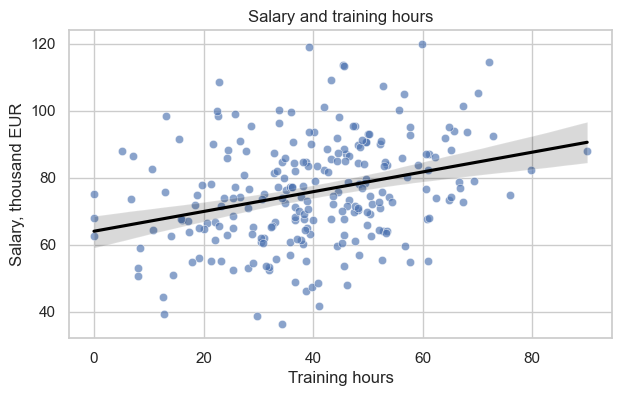

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")

In [5]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     24.02
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           1.76e-06
Time:                        19:58:04   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.577     24.

In [15]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
training_sd = df["training_hours"].std()
effect_per_hour = slope
print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Estimated salary change per additional training hour: {effect_per_hour:.2f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Estimated salary change per additional training hour: 0.30 thousand EUR


In [7]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
predictions = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(predictions[["mean", "mean_ci_lower", "mean_ci_upper"]])

,training_hours,mean,mean_ci_lower,mean_ci_upper
0,10,66.922063,62.920192,70.923934
1,40,75.775371,73.870950,77.679793
2,80,87.579782,82.431712,92.727853


[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

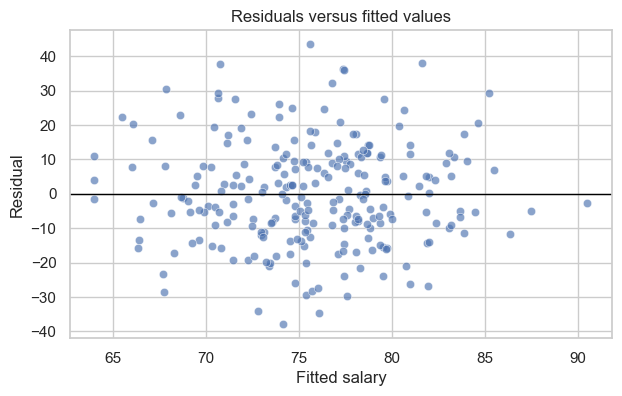

In [8]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")

## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.